# GrC Image Matting on CBIS-DDSM - Layer 1 and Layer 2 Templates

Layer 1 texture extraction at every scale, the patient-grouped train/validation/test split, and K-Means template banks on the six-channel (LIPW + LBPW at 3x3, 5x5, 7x7) representation.
K is not chosen here. The bank holds K = 8, 12, 16; Notebook 3 selects K by validation balanced accuracy of the full Layer 4 classifier.

## State restoration

In [ ]:
!pip install -q opencv-python scikit-learn scipy tqdm joblib

import os, json, random, warnings, time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
from numpy.lib.stride_tricks import sliding_window_view
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedGroupKFold
import joblib
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_ROOT = "/content/drive/MyDrive/cbis_ddsm_grc_project_v3_dicom"
CONFIG = json.load(open(os.path.join(DRIVE_ROOT, "config.json")))
globals().update(CONFIG)
SEED = CONFIG["SEED"]
random.seed(SEED); np.random.seed(SEED)
print("Config loaded. Patch sizes:", PATCH_SIZES, "| K bank:", [8, 12, 16])

Mounted at /content/drive
Config loaded. Patch sizes: [3, 5, 7] | K bank: [8, 12, 16]


In [2]:
final_df_loaded = pd.read_csv(os.path.join(RESULTS_DIR, "final_df_loaded.csv"))
metadata_df     = pd.read_csv(os.path.join(PREPROCESSED_DIR, "preprocessing_metadata.csv"))
roi_arch    = np.load(os.path.join(PREPROCESSED_DIR, "rois.npz"))
trimap_arch = np.load(os.path.join(TRIMAPS_DIR, "trimaps.npz"))

preprocessed_results = {}
lesion_of = dict(zip(metadata_df['image_id'], metadata_df['lesion_key']))
for iid in roi_arch.files:
    preprocessed_results[iid] = {
        'image_id': iid,
        'roi'     : roi_arch[iid],
        'trimap'  : trimap_arch[iid] if iid in trimap_arch.files else None,
        'lesion_key': lesion_of.get(iid),
    }
print(f"Restored {len(preprocessed_results)} images")

Restored 1067 images


## Sections 5 & 6 - Layer 1 fuzzy texture extraction

Identical to the MIAS implementation: LIPW/LBPW maps at 3×3, 5×5 and 7×7.
The 5×5 map alone is **Modification 2**; the three-scale stack is **Modification 4**.

In [ ]:
def apply_layer1(roi, patch_size, lambda_val=None):
    lam = LAMBDA_VAL if lambda_val is None else lambda_val
    half = patch_size // 2
    padded = np.pad(roi, half, mode='reflect').astype(np.float32)
    patches = sliding_window_view(padded, (patch_size, patch_size))

    lipw = 1.0 / (1.0 + np.exp(-lam * (patches - 0.5)))
    lipw_map = lipw.mean(axis=(-2, -1)).astype(np.float32)               

    centre = patches[:, :, half, half][:, :, None, None]
    centre = np.where(np.abs(centre - 0.5) < 1e-6, centre + 1e-6, centre)
    xor = patches + centre - 2 * patches * centre
    lbpw = 1.0 / (1.0 + np.exp(-lam * (xor - 0.5)))
    lbpw[:, :, half, half] = 0.0
    lbpw_map = (lbpw.sum(axis=(-2, -1)) / (patch_size * patch_size - 1)).astype(np.float32)

    return lipw_map, lbpw_map

_t = np.linspace(0, 1, 25).reshape(5, 5).astype(np.float32)
_l, _b = apply_layer1(_t, 3)
print(f"LIPW range on a 0..1 ramp: {_l.min():.4f} to {_l.max():.4f}")
print(f"LBPW range on a 0..1 ramp: {_b.min():.4f} to {_b.max():.4f}")
print("Note: sigmoid compresses values toward 0.5. This matters for Layer 2 "
      "and is why the matcher must use signed weights, not fixed 0.7/0.3 cuts.")


LIPW range on a 0..1 ramp: 0.1697 to 0.8303
LBPW range on a 0..1 ramp: 0.1815 to 0.5000
Note: sigmoid compresses values toward 0.5. This matters for Layer 2 and is why the matcher must use signed weights, not fixed 0.7/0.3 cuts.


In [ ]:
layer1_maps = {ps: {} for ps in PATCH_SIZES}
t0 = time.time()
for _, row in tqdm(final_df_loaded.iterrows(), total=len(final_df_loaded), desc="Layer 1"):
    iid = row['image_id']
    if iid not in preprocessed_results:
        continue
    roi = preprocessed_results[iid]['roi']
    for ps in PATCH_SIZES:
        lipw, lbpw = apply_layer1(roi, ps)
        layer1_maps[ps][iid] = {'lipw': lipw, 'lbpw': lbpw}

total = len(final_df_loaded) * len(PATCH_SIZES)
print(f"\n{total} maps in {time.time()-t0:.1f}s")
for ps in PATCH_SIZES:
    np.savez_compressed(os.path.join(OUTPUTS_DIR, f"layer1_ms_lipw_{ps}x{ps}.npz"),
                        **{k: v['lipw'] for k, v in layer1_maps[ps].items()})
    np.savez_compressed(os.path.join(OUTPUTS_DIR, f"layer1_ms_lbpw_{ps}x{ps}.npz"),
                        **{k: v['lbpw'] for k, v in layer1_maps[ps].items()})
print("Saved Layer 1 maps for all scales.")

Layer 1: 100%|██████████| 1067/1067 [00:57<00:00, 18.46it/s]



3201 maps in 57.8s
Saved Layer 1 maps for all scales.


## Sections 7 & 8 - Patient-grouped split and six-channel K-Means template banks

- Patient-grouped and class-stratified into train / validation / test (about 60/15/25), so no patient, lesion or view crosses a boundary. Train fits everything that is learned (channel statistics, templates, SVM). Validation is used for model selection. Test is touched only for the final results.
- The six maps (LIPW and LBPW at 3x3, 5x5, 7x7) are stacked into an H x W x 6 array and each channel is z-scored with statistics from training images only.
- **Templates:** A template is a 6 x 5 x 5 patch (150 values). Patches are mean-centred per channel before K-Means, and the signed cosine match is applied per-channel-centred as well. This matters: with joint centring, the brightness level of each channel dominates the patch, K-Means mostly learns brightness, and the sign-pattern matcher, collapses K templates into a handful of distinct patterns. 

In [5]:
# Patient-grouped, class-stratified train / val / test split (about 60 / 15 / 25)
def patient_grouped_split(df, seed=42, test_folds=4, val_folds=5, out_path=None):
    df = df.reset_index(drop=True)
    y, g = df['class'].values, df['patient_id'].values

    sgkf = StratifiedGroupKFold(n_splits=test_folds, shuffle=True, random_state=seed)
    rest_idx, test_idx = next(sgkf.split(df, y, g))

    rest = df.iloc[rest_idx].reset_index(drop=True)
    sgkf2 = StratifiedGroupKFold(n_splits=val_folds, shuffle=True, random_state=seed)
    tr_idx, val_idx = next(sgkf2.split(rest, rest['class'].values, rest['patient_id'].values))

    parts = {'train': rest.iloc[tr_idx], 'val': rest.iloc[val_idx], 'test': df.iloc[test_idx]}

    pats = {k: set(v['patient_id']) for k, v in parts.items()}
    les  = {k: set(v['lesion_key']) for k, v in parts.items()}
    ids  = {k: set(v['image_id'])   for k, v in parts.items()}
    for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
        assert not (pats[a] & pats[b]), f"PATIENT LEAKAGE {a}/{b}"
        assert not (les[a] & les[b]),   f"LESION LEAKAGE {a}/{b}"
        assert not (ids[a] & ids[b]),   f"IMAGE LEAKAGE {a}/{b}"
    assert sum(len(v) for v in ids.values()) == len(df), "images lost or duplicated"

    report = {}
    for k, v in parts.items():
        report[k] = {'images': int(len(v)), 'lesions': len(les[k]), 'patients': len(pats[k]),
                     'per_class': v['class'].value_counts().to_dict()}
        print(f"{k:<5}: {report[k]}")

    out = {'train_ids': sorted(ids['train']), 'val_ids': sorted(ids['val']),
           'test_ids': sorted(ids['test']),
           'train_lesions': sorted(les['train']), 'val_lesions': sorted(les['val']),
           'test_lesions': sorted(les['test']),
           'train_patients': sorted(pats['train']), 'val_patients': sorted(pats['val']),
           'test_patients': sorted(pats['test']), 'report': report, 'seed': seed}
    if out_path:
        with open(out_path, 'w') as f:
            json.dump(out, f, indent=2)
    return out

print("patient_grouped_split defined.")


patient_grouped_split defined.


In [6]:
# Run the split
split = patient_grouped_split(final_df_loaded, seed=SEED,
                              out_path=os.path.join(RESULTS_DIR, "train_test_split.json"))
train_ids = set(split['train_ids'])
val_ids   = set(split['val_ids'])
test_ids  = set(split['test_ids'])
print(f"\nTrain {len(train_ids)} | Val {len(val_ids)} | Test {len(test_ids)} images")
print("No patient, lesion or image is shared between train, validation and test.")


train: {'images': 642, 'lesions': 405, 'patients': 367, 'per_class': {'CIRC': 217, 'MISC': 216, 'SPIC': 209}}
val  : {'images': 156, 'lesions': 105, 'patients': 92, 'per_class': {'SPIC': 65, 'MISC': 47, 'CIRC': 44}}
test : {'images': 269, 'lesions': 171, 'patients': 152, 'per_class': {'MISC': 92, 'CIRC': 89, 'SPIC': 88}}

Train 642 | Val 156 | Test 269 images
No patient, lesion or image is shared between train, validation and test.


In [ ]:
old_p = "/content/drive/MyDrive/cbis_ddsm_grc_project_v2/results/train_test_split.json"
if os.path.exists(old_p):
    old = json.load(open(old_p))
    for k in ('train', 'val', 'test'):
        a, b = set(old[f'{k}_ids']), set(split[f'{k}_ids'])
        print(f"{k:<5}: identical to the Kaggle run: {a == b}  (only in old {len(a - b)}, only in new {len(b - a)})")
else:
    print("The v2 split file was not found, so the split cannot be compared.")


train: identical to the Kaggle run: True  (only in old 0, only in new 0)
val  : identical to the Kaggle run: True  (only in old 0, only in new 0)
test : identical to the Kaggle run: True  (only in old 0, only in new 0)


In [8]:
# Six-channel stack with train-only channel statistics
CHANNELS = [(ps, kind) for ps in PATCH_SIZES for kind in ('lipw', 'lbpw')]   # 6 channels
print("Channel order:", CHANNELS)

def compute_channel_stats(ids):
    n = 0
    s  = np.zeros(len(CHANNELS), np.float64)
    s2 = np.zeros(len(CHANNELS), np.float64)
    for iid in ids:
        if iid not in layer1_maps[PATCH_SIZES[0]]:
            continue
        for c, (ps, kind) in enumerate(CHANNELS):
            m = layer1_maps[ps][iid][kind].astype(np.float64)
            s[c]  += m.sum()
            s2[c] += (m ** 2).sum()
        n += layer1_maps[PATCH_SIZES[0]][iid]['lipw'].size
    mean = s / n
    std  = np.sqrt(np.maximum(s2 / n - mean ** 2, 1e-12))
    return mean.astype(np.float32), std.astype(np.float32)

CH_MEAN, CH_STD = compute_channel_stats(train_ids)      # TRAIN images only
with open(os.path.join(MODELS_DIR, "channel_stats.json"), 'w') as f:
    json.dump({'channels': [list(c) for c in CHANNELS],
               'mean': CH_MEAN.tolist(), 'std': CH_STD.tolist(),
               'fit_on': 'train images only'}, f, indent=2)
print("Channel means:", np.round(CH_MEAN, 4))
print("Channel stds :", np.round(CH_STD, 4))

def build_stack(iid, standardise=True):
    """H x W x 6 float32 stack of the six Layer-1 maps (z-scored with train statistics)."""
    chans = [layer1_maps[ps][iid][kind] for ps, kind in CHANNELS]
    st = np.stack(chans, axis=2).astype(np.float32)
    if standardise:
        st = (st - CH_MEAN[None, None, :]) / CH_STD[None, None, :]
    return st


Channel order: [(3, 'lipw'), (3, 'lbpw'), (5, 'lipw'), (5, 'lbpw'), (7, 'lipw'), (7, 'lbpw')]
Channel means: [0.5181 0.4351 0.5182 0.4471 0.5182 0.4542]
Channel stds : [0.1724 0.084  0.1536 0.0757 0.1426 0.0704]


In [ ]:
# Extract six-channel patches (6 x 5 x 5 = 150 values) from TRAIN images only
WIN = PATCH_SINGLE           
N_CH = len(CHANNELS)

def window_view(stack, ps=None):
    ps = WIN if ps is None else ps
    half = ps // 2
    padded = np.pad(stack, ((half, half), (half, half), (0, 0)), mode='reflect')
    # shape (H, W, C, ps, ps), a view (no copy)
    return sliding_window_view(padded, (ps, ps), axis=(0, 1))

def extract_patches(ids, max_per_img=200, standardise=True):
    out = []
    rng = np.random.default_rng(SEED)
    for iid in tqdm(sorted(ids), desc="patches"):
        if iid not in preprocessed_results or iid not in layer1_maps[PATCH_SIZES[0]]:
            continue
        tm = preprocessed_results[iid]['trimap']
        if tm is None:
            continue
        stack = build_stack(iid, standardise)
        if stack.shape[:2] != tm.shape:
            tm = cv2.resize(tm, (stack.shape[1], stack.shape[0]), interpolation=cv2.INTER_NEAREST)
        win = window_view(stack)
        for val in (255, 0):                 # definite mass, definite background
            pos = np.argwhere(tm == val)
            if len(pos) == 0:
                continue
            if len(pos) > max_per_img:
                pos = pos[rng.choice(len(pos), max_per_img, replace=False)]
            out.append(win[pos[:, 0], pos[:, 1]].reshape(len(pos), -1))
    return np.concatenate(out).astype(np.float32)

all_patches = extract_patches(train_ids)
print(f"\nExtracted {all_patches.shape[0]} patches of dim {all_patches.shape[1]} "
      f"({N_CH} channels x {WIN} x {WIN})")
print(f"Value range {all_patches.min():.3f} to {all_patches.max():.3f}, "
      f"mean {all_patches.mean():.3f}, std {all_patches.std():.3f}")


patches: 100%|██████████| 642/642 [00:00<00:00, 694.07it/s]



Extracted 215801 patches of dim 150 (6 channels x 5 x 5)
Value range -5.370 to 4.467, mean 0.043, std 0.947


In [ ]:
# Per-channel centring and the signed cosine matcher 
def center_patches(P, mode='channel'):
    """P: n x (C*ps*ps). 'channel' removes each channel's own patch mean (texture pattern only)."""
    P = P.reshape(len(P), N_CH, -1)
    if mode == 'channel':
        P = P - P.mean(axis=2, keepdims=True)
    elif mode == 'joint':
        P = P - P.reshape(len(P), -1).mean(axis=1)[:, None, None]
    return P.reshape(len(P), -1)

def match_templates_signed_stack(stack, templates, mode='channel'):
    """stack: H x W x C; templates: K x C x ps x ps. Returns H x W x K scores in [0, 1]."""
    h, w, C = stack.shape
    K, _, ps, _ = templates.shape
    pf = window_view(stack, ps).reshape(h * w, C * ps * ps).astype(np.float32)
    Tc = center_patches(templates.reshape(K, -1).astype(np.float32), mode)
    Pc = center_patches(pf, mode)
    W = np.sign(Tc); W[W == 0] = 1.0
    num   = Pc @ W.T
    denom = np.linalg.norm(Pc, axis=1, keepdims=True) * np.linalg.norm(W, axis=1)[None, :] + 1e-8
    return (((num / denom) + 1.0) * 0.5).reshape(h, w, K).astype(np.float32)

CENTER_MODE = 'channel'

_iid = sorted(train_ids)[0]
_st = build_stack(_iid)
_win = window_view(_st)
_i, _j = _st.shape[0] // 2, _st.shape[1] // 2
_vec = _win[_i, _j].reshape(-1)
_tmpl = np.stack([_vec.reshape(N_CH, WIN, WIN),
                  -_vec.reshape(N_CH, WIN, WIN)]).astype(np.float32)   # a template and its negative
_sm = match_templates_signed_stack(_st, _tmpl, CENTER_MODE)
assert _sm.shape == (_st.shape[0], _st.shape[1], 2)
assert _sm[_i, _j, 0] > 0.8 and _sm[_i, _j, 1] < 0.2, "matcher / extractor layout mismatch"
print(f"Matcher ready (centre mode = {CENTER_MODE}). Self-match {_sm[_i, _j, 0]:.3f}, "
      f"anti-match {_sm[_i, _j, 1]:.3f}.")


Matcher ready (centre mode = channel). Self-match 0.894, anti-match 0.106.


In [ ]:
# Fit the template bank on TRAIN patches
K_CANDIDATES = [8, 12, 16]
P_centred = center_patches(all_patches, CENTER_MODE)

def fit_bank_entry(k, n_init=5):
    km = KMeans(n_clusters=k, init='k-means++', n_init=n_init, random_state=SEED).fit(P_centred)
    return km, km.cluster_centers_.reshape(k, N_CH, WIN, WIN).astype(np.float32)

def describe_bank_entry(tmpl, ids):
    """Diversity and match separation on validation images. Descriptive only, not used to pick K."""
    cls_of = dict(zip(final_df_loaded['image_id'], final_df_loaded['class']))
    per_class = {c: [] for c in TARGET_CLASSES}
    wins = np.zeros(len(tmpl), np.int64)
    for iid in sorted(ids):
        if iid not in layer1_maps[PATCH_SIZES[0]] or iid not in preprocessed_results:
            continue
        tm = preprocessed_results[iid]['trimap']
        if tm is None:
            continue
        sm = match_templates_signed_stack(build_stack(iid), tmpl, CENTER_MODE)
        wins += np.bincount(np.argmax(sm, axis=2).ravel(), minlength=len(tmpl))
        if sm.shape[:2] != tm.shape:
            tm = cv2.resize(tm, (sm.shape[1], sm.shape[0]), interpolation=cv2.INTER_NEAREST)
        m, b = (tm == 255), (tm == 0)
        if m.sum() == 0 or b.sum() == 0:
            continue
        per_class[cls_of[iid]].append(np.abs(sm[m].mean(axis=0) - sm[b].mean(axis=0)).mean())
    score = float(np.mean([np.mean(v) for v in per_class.values() if v]))
    effective = int((wins / wins.sum() >= 0.02).sum())
    Tc = center_patches(tmpl.reshape(len(tmpl), -1), CENTER_MODE)
    distinct = len({tuple(r) for r in np.sign(Tc).astype(int)})
    return score, effective, distinct

bank = {}
print(f"Templates fit on {len(train_ids)} train images; described on {len(val_ids)} validation images.\n")
print(f"{'K':<5}{'pooled diff (val)':>20}{'effective (>=2% px)':>22}{'distinct patterns':>20}")
print("-" * 68)
for k in K_CANDIDATES:
    km_k, tmpl_k = fit_bank_entry(k)
    sc, eff, dist = describe_bank_entry(tmpl_k, val_ids)
    bank[k] = {'km': km_k, 'tmpl': tmpl_k, 'score': sc, 'effective': eff, 'distinct': dist}
    print(f"{k:<5}{sc:>20.5f}{eff:>14d} / {k:<4}{dist:>13d} / {k}")
print("\nK is chosen in Notebook 3 by validation balanced accuracy of the full classifier.")


Templates fit on 642 train images; described on 156 validation images.

K       pooled diff (val)   effective (>=2% px)   distinct patterns
--------------------------------------------------------------------
8                 0.02767             8 / 8               8 / 8
12                0.02639            12 / 12             12 / 12
16                0.02679            16 / 16             16 / 16

K is chosen in Notebook 3 by validation balanced accuracy of the full classifier.


In [ ]:
for k, e in bank.items():
    assert e['distinct'] >= int(0.75 * k), f"K={k}: only {e['distinct']} distinct patterns - templates collapsing"
    assert e['effective'] >= int(0.5 * k), f"K={k}: only {e['effective']} templates win >=2% of pixels"
    tf = e['tmpl'].reshape(k, -1)
    dm = squareform(pdist(tf)); iu = np.triu_indices(k, 1)
    print(f"K={k:<3} values {tf.min():.3f}..{tf.max():.3f} (std {tf.std():.3f}) | "
          f"pairwise dist min {dm[iu].min():.3f}, mean {dm[iu].mean():.3f}")
print("Template bank health check passed.")


K=8   values -1.074..0.674 (std 0.330) | pairwise dist min 4.115, mean 5.978
K=12  values -1.189..0.727 (std 0.357) | pairwise dist min 2.548, mean 6.277
K=16  values -1.254..0.768 (std 0.381) | pairwise dist min 2.627, mean 6.590
Template bank health check passed.


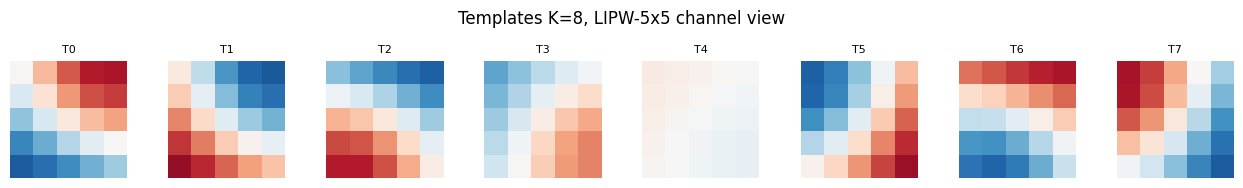

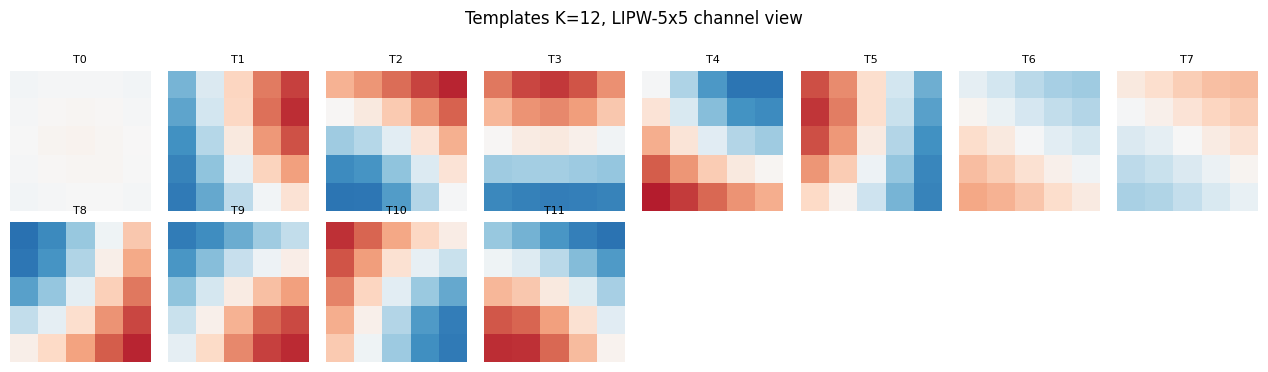

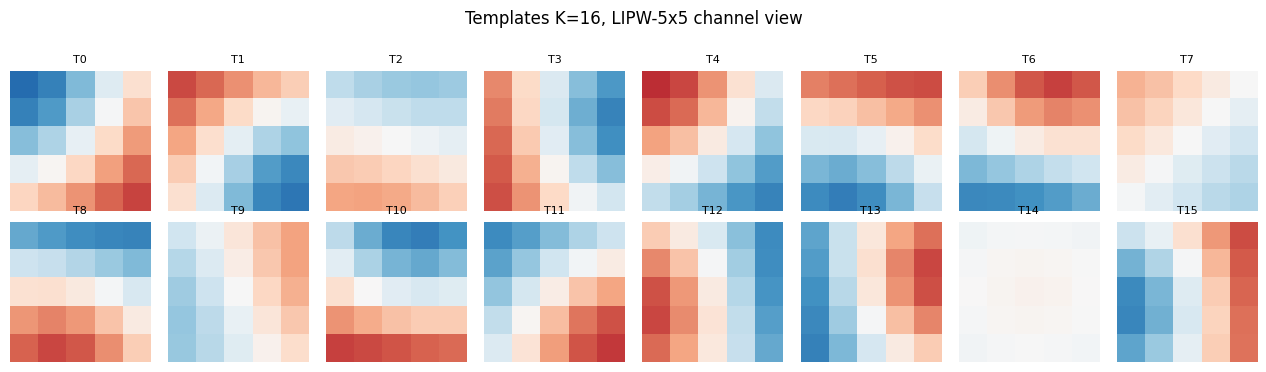

Saved templates_K*.npy, kmeans_K*.joblib, template_meta.json, channel_stats.json


In [ ]:
# Save the template bank
for k, e in bank.items():
    np.save(os.path.join(MODELS_DIR, f"templates_K{k}.npy"), e['tmpl'])      
    joblib.dump(e['km'], os.path.join(MODELS_DIR, f"kmeans_K{k}.joblib"))
with open(os.path.join(MODELS_DIR, "template_meta.json"), 'w') as f:
    json.dump({'k_candidates': K_CANDIDATES, 'window': int(WIN),
               'channels': [list(c) for c in CHANNELS],
               'template_shape': [N_CH, int(WIN), int(WIN)],
               'center_mode': CENTER_MODE, 'standardised': True,
               'channel_stats_file': 'channel_stats.json',
               'source': 'six-channel patches from train images only',
               'n_patches': int(all_patches.shape[0]),
               'selection': 'K chosen in Notebook 3 by validation balanced accuracy of the full classifier',
               'bank_description_val': {int(k): {'pooled_diff': e['score'], 'effective': e['effective'],
                                                 'distinct_patterns': e['distinct']}
                                        for k, e in bank.items()}}, f, indent=2)

for k, e in bank.items():
    t = e['tmpl']
    ncol = min(k, 8); nrow = int(np.ceil(k / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(1.6 * ncol, 1.8 * nrow))
    axes = np.atleast_1d(axes).ravel()
    vmax = np.abs(t.mean(axis=1)).max()
    for i in range(k):
        axes[i].imshow(t[i][2], cmap='RdBu_r', vmin=-vmax, vmax=vmax)     # LIPW 5x5 channel
        axes[i].set_title(f"T{i}", fontsize=8); axes[i].axis('off')
    for i in range(k, len(axes)): axes[i].axis('off')
    plt.suptitle(f"Templates K={k}, LIPW-5x5 channel view", y=1.02); plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"section7_templates_K{k}.png"), dpi=130, bbox_inches='tight')
    plt.show()
print("Saved templates_K*.npy, kmeans_K*.joblib, template_meta.json, channel_stats.json")


In [14]:
# Verification
def verify_section58():
    sp = json.load(open(os.path.join(RESULTS_DIR, "train_test_split.json")))
    P = {k: set(sp[f'{k}_patients']) for k in ('train', 'val', 'test')}
    meta = json.load(open(os.path.join(MODELS_DIR, "template_meta.json")))
    checks = {
        "Layer 1 all scales"     : all(len(layer1_maps[ps]) == len(final_df_loaded)
                                       for ps in PATCH_SIZES),
        "Layer 1 saved"          : all(os.path.exists(os.path.join(
                                       OUTPUTS_DIR, f"layer1_ms_{kind}_{ps}x{ps}.npz"))
                                       for ps in PATCH_SIZES for kind in ('lipw', 'lbpw')),
        "Split patient-disjoint" : not (P['train'] & P['val'] or P['train'] & P['test']
                                        or P['val'] & P['test']),
        "Validation set present" : len(sp['val_ids']) > 0,
        "Split covers all images": len(sp['train_ids']) + len(sp['val_ids']) + len(sp['test_ids'])
                                   == len(final_df_loaded),
        "Channel stats saved"    : os.path.exists(os.path.join(MODELS_DIR, "channel_stats.json")),
        "Bank saved (all K)"     : all(os.path.exists(os.path.join(MODELS_DIR, f"templates_K{k}.npy"))
                                       for k in K_CANDIDATES),
        "Meta lists the bank"    : meta['k_candidates'] == K_CANDIDATES
                                   and meta['center_mode'] == 'channel',
        "Templates are 6-channel": all(bank[k]['tmpl'].shape == (k, N_CH, WIN, WIN) for k in K_CANDIDATES),
        "Templates not collapsed": all(bank[k]['distinct'] >= int(0.75 * k) for k in K_CANDIDATES),
    }
    print("=" * 52); print("SECTIONS 5-8 VERIFICATION"); print("=" * 52)
    ok = True
    for k, v in checks.items():
        print(f"  {'OK ' if v else 'FAIL'}  {k}"); ok = ok and v
    print("=" * 52)
    print("Proceed to notebook 3." if ok else "Review failures.")
    return ok

verify_section58()


SECTIONS 5-8 VERIFICATION
  OK   Layer 1 all scales
  OK   Layer 1 saved
  OK   Split patient-disjoint
  OK   Validation set present
  OK   Split covers all images
  OK   Channel stats saved
  OK   Bank saved (all K)
  OK   Meta lists the bank
  OK   Templates are 6-channel
  OK   Templates not collapsed
Proceed to notebook 3.


True